# Neural Networks Hands-On: Handwritten Digits (MNIST) in PyTorch

**Goal:** train a neural network to read handwritten digits, and along the way learn

1. why we split data into **training / validation / test** sets,
2. what **backpropagation** actually does (one step at a time),
3. how to **measure success** honestly (beyond a single accuracy number), and
4. how models **overfit** and **fail** when data changes.

Throughout, look for **Predict first:** prompts. Write down your guess *before* running the cell.

In [1]:
%pip install torch torchvision



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device)

Using cpu


## 1. Look at the data

MNIST has 70,000 grayscale images of handwritten digits, each 28 × 28 pixels.
To the computer, each image is just **784 numbers** (0 = black, 255 = white).

In [3]:
raw_train = datasets.MNIST("data", train=True, download=True)   # no transform: raw images
print("Training images:", raw_train.data.shape)                   # 60000 x 28 x 28
print("Labels:", raw_train.targets[:10].tolist())

Training images: torch.Size([60000, 28, 28])
Labels: [5, 0, 4, 1, 9, 2, 1, 3, 1, 4]


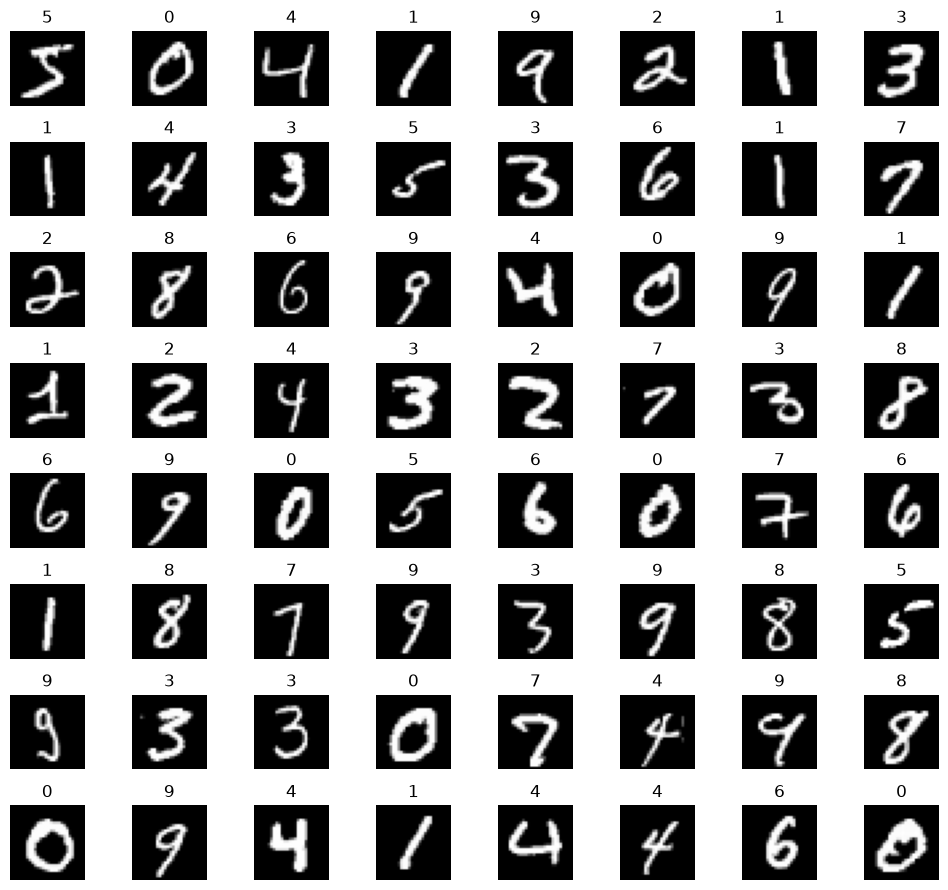

In [4]:
fig, axes = plt.subplots(8, 8, figsize=(10, 9))
for ax, i in zip(axes.flat, range(64)):
    ax.imshow(raw_train.data[i], cmap="gray")
    ax.set_title(int(raw_train.targets[i]))
    ax.axis("off")
plt.tight_layout(); plt.show()

An image really is just a grid of numbers. Here is the top-left corner of the first image (rows 4–13, columns 4–13):

In [5]:
print(raw_train.data[0][4:14, 4:14].numpy())

[[  0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   3  18]
 [  0   0   0   0  30  36  94 154 170 253]
 [  0   0   0  49 238 253 253 253 253 253]
 [  0   0   0  18 219 253 253 253 253 253]
 [  0   0   0   0  80 156 107 253 253 205]
 [  0   0   0   0   0  14   1 154 253  90]
 [  0   0   0   0   0   0   0 139 253 190]
 [  0   0   0   0   0   0   0  11 190 253]
 [  0   0   0   0   0   0   0   0  35 241]]


**Class balance.** Are the ten digits roughly equally common? (This matters later for "measuring success.")

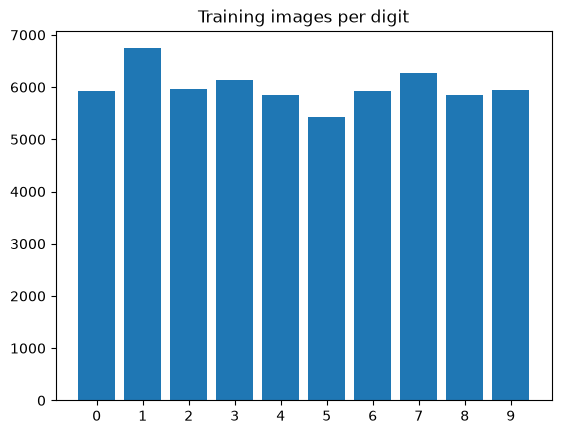

{0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}


In [6]:
counts = torch.bincount(raw_train.targets, minlength=10)
plt.bar(range(10), counts); plt.xticks(range(10)); plt.title("Training images per digit"); plt.show()
print({d: int(c) for d, c in enumerate(counts)})

**Scaling the inputs.** Networks train better when inputs are centered near 0 with spread near 1.
We compute the mean and standard deviation **from the training data only**. Using test data here
would leak information about the test set into the model (a subtle form of cheating called *data leakage*).

In [7]:
pixels = raw_train.data.float() / 255
MEAN, STD = pixels.mean().item(), pixels.std().item()
print(f"mean = {MEAN:.4f}, std = {STD:.4f}")

transform = transforms.Compose([
    transforms.ToTensor(),                 # 0–255 integers → 0.0–1.0 floats
    transforms.Normalize((MEAN,), (STD,)), # center and scale
])
full_train = datasets.MNIST("data", train=True, download=True, transform=transform)
test_set   = datasets.MNIST("data", train=False, download=True, transform=transform)

mean = 0.1307, std = 0.3081


## 2. Training, validation, and test sets

| Set | Size | Analogy | Used for |
|---|---|---|---|
| **Training** | 50,000 | Homework | Adjusting the weights (learning) |
| **Validation** | 10,000 | Practice exam | Choosing settings: learning rate, size, number of epochs |
| **Test** | 10,000 | Final exam | **One** honest estimate of real-world performance, at the very end |

If you peek at the test set while making choices, your final score is no longer an unbiased estimate.
It's like an auditor letting the client pick which transactions get sampled.

MNIST ships with 60,000 training and 10,000 test images. We carve a validation set out of the training images.

In [8]:
train_set, val_set = random_split(full_train, [50_000, 10_000],
                                  generator=torch.Generator().manual_seed(42))
print(len(train_set), len(val_set), len(test_set))

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
train_eval_loader = DataLoader(Subset(train_set, range(10_000)), batch_size=1000)  # for measuring training accuracy
val_loader   = DataLoader(val_set, batch_size=1000)
test_loader  = DataLoader(test_set, batch_size=1000)

50000 10000 10000


**Baseline.** Before building anything clever, how well does a dumb rule do?
The simplest rule: always guess the most common digit in the training data.

**Predict first:** what accuracy will "always guess the most common digit" get on the validation set?

In [9]:
train_labels = full_train.targets[train_set.indices]
val_labels = full_train.targets[val_set.indices]
most_common = int(torch.bincount(train_labels).argmax())
baseline_acc = (val_labels == most_common).float().mean().item()
print(f"Always guess {most_common}: validation accuracy = {baseline_acc:.1%}")

Always guess 1: validation accuracy = 11.3%


Any model we build must beat this baseline, and beat it by a lot.

## 3. The model

A *multilayer perceptron* (MLP):

`784 pixels → 128 hidden neurons (ReLU) → 10 outputs (one score per digit)`

Each hidden neuron computes a weighted sum of all 784 pixels, adds a bias, then applies ReLU (negative → 0).
The 10 outputs are raw scores called **logits**. A logit is a raw score before applying the softmax function, which converts the logits into probabilities. The highest score is the prediction.

In [10]:
# Should we use a simple model or complex? 
hidden_model_nodes = 2 # or 16, 128, 256, 512, 1024...

class MLP(nn.Module):
    def __init__(self, hidden=128, dropout=0.0, relu=True):
        super().__init__()
        # Flatten reshapes the 28x28 image into a 784-length vector. 
        # The first Linear layer computes 128 weighted sums of the 784 pixels, adds a bias, and applies ReLU (if relu=True). 
        #   ReLU is a non-linear activation function that outputs the input if it's positive, and 0 otherwise.
        # The second Linear layer computes 10 weighted sums of the 128 hidden neurons, adds a bias, and outputs 10 raw scores (logits).
        layers = [nn.Flatten(), nn.Linear(784, hidden)]
        if relu:
            layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(hidden, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(42)
model = MLP(hidden=hidden_model_nodes, dropout=0.5, relu=True).to(device)

print(model)
print("Parameters (weights + biases):", f"{count_params(model):,}")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=2, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=2, out_features=10, bias=True)
  )
)
Parameters (weights + biases): 1,600


**Your turn:** You can verify the parameter count by hand. 

Layer 1 has 784 × 128 weights + 128 biases.

Layer 2 has 128 (or 256, 512, 1024) × 10 + 10.

**Predict first:** the weights are random right now. What accuracy should the untrained model get?

In [11]:
def evaluate(model, loader):
    """Return (average loss, accuracy) over a data loader. No learning happens here."""
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
            correct += (logits.argmax(dim=1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

loss, acc = evaluate(model, val_loader)
print(f"Untrained: loss = {loss:.3f}, accuracy = {acc:.1%}")
print(f"For reference, ln(10) = {np.log(10):.3f}")

Untrained: loss = 2.387, accuracy = 9.6%
For reference, ln(10) = 2.303


The **loss** (cross-entropy) measures how much probability the model puts on the correct answer:
loss = −ln(probability of correct digit). A clueless model spreads probability evenly (1/10 each), so
its loss is about −ln(0.1) = 2.30. A perfect, confident model has loss near 0.

Cross-entropy loss is a standard choice for classification problems.
We use loss to train the model, and accuracy to measure success. Loss is more sensitive than accuracy, especially early in training.

## 4. Backpropagation, one step at a time


The idea on the real network

Backprop does exactly this for all 101,770 weights at once, using the chain rule layer by layer from the output back to the input.

In [12]:
torch.manual_seed(0)
model = MLP().to(device)
x, y = next(iter(train_loader))          # one batch of 64 images
x, y = x.to(device), y.to(device)

# 1. Forward pass: images → scores → loss
logits = model(x)
loss = F.cross_entropy(logits, y)
print(f"Loss before: {loss.item():.4f}")

# 2. Backward pass: compute the gradient for every weight
first_layer = model.net[1]
print("Gradient before backward():", first_layer.weight.grad)
loss.backward()
print("Gradient shape:", tuple(first_layer.weight.grad.shape), "(one number per weight)")

# 3. Update: step every weight a little bit opposite its gradient
lr = 0.1
with torch.no_grad():
    for p in model.parameters():
        p -= lr * p.grad
model.zero_grad()                         # clear gradients, or they accumulate

# 4. Same batch again: did the loss go down?
print(f"Loss after one step: {F.cross_entropy(model(x), y).item():.4f}")

Loss before: 2.2595
Gradient before backward(): None
Gradient shape: (128, 784) (one number per weight)
Loss after one step: 1.8996


That's one step of learning. Training is just this loop repeated thousands of times on different batches.
In practice PyTorch's optimizer does step 3 for us (`optimizer.step()`).

**Sanity check used by practitioners: overfit one batch.** If the code is correct, the model should be able to
memorize a single batch of 64 images, driving the loss close to 0. If it can't, there's a bug.

In [13]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
for step in range(1, 101):
    optimizer.zero_grad()
    loss = F.cross_entropy(model(x), y)
    loss.backward()
    optimizer.step()
    if step in (1, 10, 25, 50, 100):
        print(f"step {step:3d}: loss on this batch = {loss.item():.4f}")

print(f"Accuracy on the memorized batch: {(model(x).argmax(1) == y).float().mean():.0%}")
print(f"Accuracy on validation set:      {evaluate(model, val_loader)[1]:.0%}")

step   1: loss on this batch = 1.8996
step  10: loss on this batch = 0.4028
step  25: loss on this batch = 0.0907
step  50: loss on this batch = 0.0308
step 100: loss on this batch = 0.0116
Accuracy on the memorized batch: 100%
Accuracy on validation set:      67%


**Question:** the model is 100% right on the batch it studied but much worse on new images. Why?
This gap between memorizing and generalizing is **overfitting**, and it's why we need separate validation and test sets.

## 5. The full training loop

One **epoch** = one pass through all 50,000 training images (782 batches of 64).
After each epoch we measure loss and accuracy on training and validation data.

In [14]:
def train(model, train_loader, val_loader, epochs=5, lr=0.1, weight_decay=0.0,
          train_eval_loader=train_eval_loader, verbose=True):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()                  # clear old gradients
            loss = F.cross_entropy(model(x), y)    # forward pass
            loss.backward()                        # backpropagation
            optimizer.step()                       # gradient descent update
        tr_loss, tr_acc = evaluate(model, train_eval_loader)
        va_loss, va_acc = evaluate(model, val_loader)
        for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[k].append(v)
        if verbose:
            print(f"epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.2%} | "
                  f"val loss {va_loss:.3f} acc {va_acc:.2%} | {time.time() - start:.0f}s")
    return history

def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
    a1.plot(epochs, history["train_loss"], "o-", label="train")
    a1.plot(epochs, history["val_loss"], "o-", label="validation")
    a1.set_title("Loss (lower is better)"); a1.set_xlabel("epoch"); a1.legend()
    a2.plot(epochs, history["train_acc"], "o-", label="train")
    a2.plot(epochs, history["val_acc"], "o-", label="validation")
    a2.set_title("Accuracy (higher is better)"); a2.set_xlabel("epoch"); a2.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

epoch  1 | train loss 0.174 acc 94.54% | val loss 0.198 acc 93.77% | 2s
epoch  2 | train loss 0.092 acc 97.37% | val loss 0.127 acc 96.27% | 2s
epoch  3 | train loss 0.060 acc 98.47% | val loss 0.104 acc 96.93% | 2s
epoch  4 | train loss 0.066 acc 97.94% | val loss 0.114 acc 96.43% | 2s
epoch  5 | train loss 0.043 acc 98.82% | val loss 0.097 acc 96.91% | 2s
epoch  6 | train loss 0.027 acc 99.29% | val loss 0.085 acc 97.48% | 2s
epoch  7 | train loss 0.038 acc 98.79% | val loss 0.100 acc 97.23% | 2s
epoch  8 | train loss 0.021 acc 99.48% | val loss 0.086 acc 97.33% | 2s


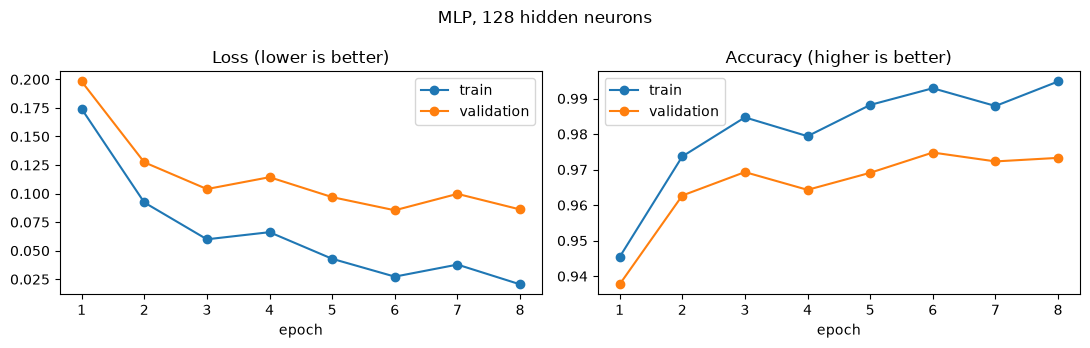

In [15]:
torch.manual_seed(42)
model = MLP().to(device)
history = train(model, train_loader, val_loader, epochs=8, lr=0.1)
plot_history(history, "MLP, 128 hidden neurons")

Your numbers will differ slightly from a classmate's: the starting weights and the batch order are random.
With plain SGD, accuracy can bounce by up to about a percentage point from epoch to epoch or run to run.
Differences that small are noise, not a better model.

**Questions:**
- Roughly when does validation accuracy stop improving much?
- Is training accuracy above validation accuracy? What does a growing gap mean?

## 6. Measuring success

We've made our choices using the validation set. **Now, and only now,** we evaluate on the test set, once.

In [16]:
def get_predictions(model, loader):
    model.eval()
    ys, preds, probs = [], [], []
    with torch.no_grad():
        for x, y in loader:
            p = F.softmax(model(x.to(device)), dim=1).cpu()   # logits → probabilities
            ys.append(y); probs.append(p); preds.append(p.argmax(1))
    return torch.cat(ys), torch.cat(preds), torch.cat(probs)

y_true, y_pred, probs = get_predictions(model, test_loader)
test_acc = (y_true == y_pred).float().mean().item()
test_baseline = (y_true == most_common).float().mean().item()
print(f"Test accuracy: {test_acc:.2%}   (baseline: {test_baseline:.2%})")
print(f"Test errors:   {(y_true != y_pred).sum().item()} out of {len(y_true):,}")

Test accuracy: 97.80%   (baseline: 11.35%)
Test errors:   220 out of 10,000


### 6a. Confusion matrix: *which* mistakes?
Rows are the true digit, columns the predicted digit. The diagonal shows correct answers; everything else is an error.

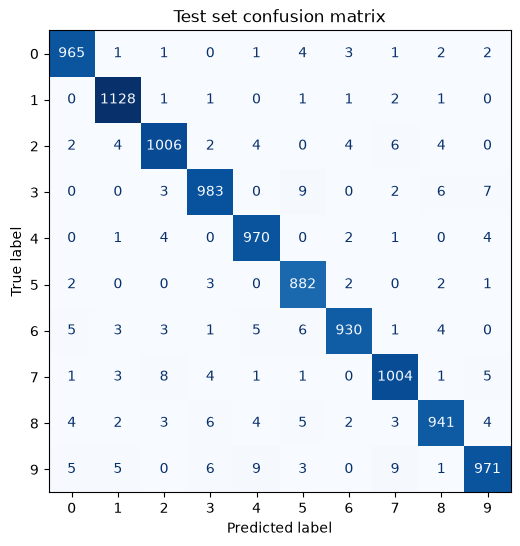

Most common mistakes:
  true 9 predicted as 7: 9 times
  true 9 predicted as 4: 9 times
  true 3 predicted as 5: 9 times
  true 7 predicted as 2: 8 times
  true 3 predicted as 9: 7 times


In [17]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Test set confusion matrix"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], i, j) for i in range(10) for j in range(10)), reverse=True)[:5]
print("Most common mistakes:")
for n, i, j in pairs:
    print(f"  true {i} predicted as {j}: {n} times")

### 6b. Precision and recall for each digit
- **Precision** for digit d: of the images the model *called* d, what fraction really were d?
- **Recall** for digit d: of the images that really *were* d, what fraction did the model find?
- **F1**: a single number that balances the two.

In [18]:
print(classification_report(y_true, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.981     0.985     0.983       980
           1      0.983     0.994     0.989      1135
           2      0.978     0.975     0.976      1032
           3      0.977     0.973     0.975      1010
           4      0.976     0.988     0.982       982
           5      0.968     0.989     0.978       892
           6      0.985     0.971     0.978       958
           7      0.976     0.977     0.976      1028
           8      0.978     0.966     0.972       974
           9      0.977     0.962     0.970      1009

    accuracy                          0.978     10000
   macro avg      0.978     0.978     0.978     10000
weighted avg      0.978     0.978     0.978     10000



### 6c. Why accuracy alone can mislead
Suppose the business question is only "Is this digit a 7?" A lazy model that *always* says "no":

In [19]:
is_seven = (y_true == 7)
lazy_acc = (~is_seven).float().mean().item()
print(f"'Never a 7' accuracy: {lazy_acc:.1%}, but recall for 7s = 0% (it finds none of them)")

'Never a 7' accuracy: 89.7%, but recall for 7s = 0% (it finds none of them)


High accuracy, useless model. This is exactly the problem in **fraud detection**, where fraud might be
well under 1% of transactions. For rare events, report precision and recall, not just accuracy.

### 6d. Look at the errors

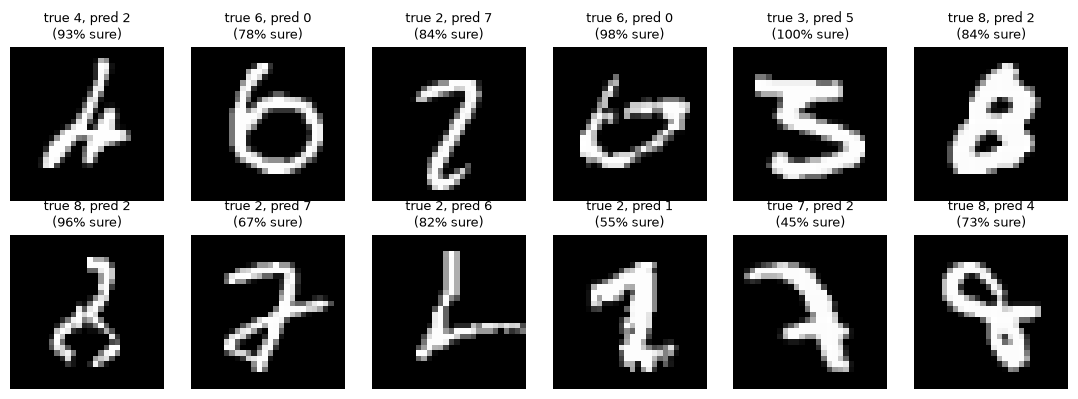

In [20]:
wrong = torch.nonzero(y_true != y_pred).flatten()[:12]
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.flat, wrong):
    img = test_set.data[i]
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ax.set_title(f"true {y_true[i].item()}, pred {y_pred[i].item()}\n({probs[i].max():.0%} sure)", fontsize=9)
plt.tight_layout(); plt.show()

**Question:** would a human get all of these right? Are some labels arguably wrong?

### 6e. Confidence: let the model say "I'm not sure"
The softmax output gives a probability for each digit. If we only accept predictions above a confidence
threshold and send the rest to a human, how accurate are the accepted ones?
This mirrors **exception-based review** in accounting: automate the routine cases and route the uncertain ones to a person.

In [21]:
confidence = probs.max(dim=1).values
rows = []
for t in [0.0, 0.5, 0.9, 0.99, 0.999]:
    keep = confidence >= t
    rows.append({"threshold": t,
                 "share handled automatically": f"{keep.float().mean():.1%}",
                 "accuracy on those": f"{(y_true[keep] == y_pred[keep]).float().mean():.2%}",
                 "sent to human review": int((~keep).sum())})
pd.DataFrame(rows)

,threshold,share handled automatically,accuracy on those,sent to human review
0,0.000,100.0%,97.80%,0
1,0.500,99.6%,98.02%,43
2,0.900,94.9%,99.45%,513
3,0.990,86.2%,99.87%,1383
4,0.999,69.5%,99.97%,3051


## 7. Experiments

For each experiment: **predict first**, run it, then explain the result.
These use the **validation** set, not the test set. (Why?)
Each run takes 30 seconds to a few minutes on a CPU.

In [22]:
results = []

def run(name, model, epochs=3, lr=0.1, weight_decay=0.0, loader=train_loader,
        train_eval=train_eval_loader, plot=False):
    torch.manual_seed(42)
    model = model.to(device)
    h = train(model, loader, val_loader, epochs=epochs, lr=lr, weight_decay=weight_decay,
              train_eval_loader=train_eval, verbose=False)
    results.append({"experiment": name, "params": count_params(model),
                    "train acc": round(h["train_acc"][-1], 4), "val acc": round(h["val_acc"][-1], 4),
                    "val loss": round(h["val_loss"][-1], 3)})
    if plot:
        plot_history(h, name)
    print(results[-1])
    return model, h

### Experiment A: learning rate
The learning rate is the step size in `w ← w − lr × gradient`.
**Predict first:** which of 0.001, 0.01, 0.1, and 1.0 works best after 3 epochs? What happens at 1.0?

In [23]:
for lr in [0.001, 0.01, 0.1, 1.0]:
    torch.manual_seed(42)
    run(f"A: lr={lr}", MLP(), lr=lr)

{'experiment': 'A: lr=0.001', 'params': 101770, 'train acc': 0.8617, 'val acc': 0.8636, 'val loss': 0.574}
{'experiment': 'A: lr=0.01', 'params': 101770, 'train acc': 0.9283, 'val acc': 0.9202, 'val loss': 0.271}
{'experiment': 'A: lr=0.1', 'params': 101770, 'train acc': 0.9706, 'val acc': 0.9575, 'val loss': 0.139}
{'experiment': 'A: lr=1.0', 'params': 101770, 'train acc': 0.4958, 'val acc': 0.492, 'val loss': 1.413}


### Experiment B: model size and the role of ReLU
**Predict first:** does a bigger hidden layer always help? What happens if we remove the ReLU?
(Hint: without ReLU, two linear layers in a row collapse into a single linear function.)

In [24]:
torch.manual_seed(42); run("B: no hidden layer (logistic regression)", nn.Sequential(nn.Flatten(), nn.Linear(784, 10)))
torch.manual_seed(42); run("B: hidden=128, no ReLU", MLP(128, relu=False))
for hidden in [16, 128, 512]:
    torch.manual_seed(42)
    run(f"B: hidden={hidden}", MLP(hidden))

{'experiment': 'B: no hidden layer (logistic regression)', 'params': 7850, 'train acc': 0.9023, 'val acc': 0.8891, 'val loss': 0.377}
{'experiment': 'B: hidden=128, no ReLU', 'params': 101770, 'train acc': 0.8948, 'val acc': 0.8828, 'val loss': 0.39}
{'experiment': 'B: hidden=16', 'params': 12730, 'train acc': 0.9343, 'val acc': 0.9239, 'val loss': 0.252}
{'experiment': 'B: hidden=128', 'params': 101770, 'train acc': 0.9706, 'val acc': 0.9575, 'val loss': 0.139}
{'experiment': 'B: hidden=512', 'params': 407050, 'train acc': 0.9771, 'val acc': 0.962, 'val loss': 0.124}


### Experiment C: overfitting with a small training set
Train on only **1,000** images for 60 epochs.
**Predict first:** what happens to training accuracy? To validation loss?

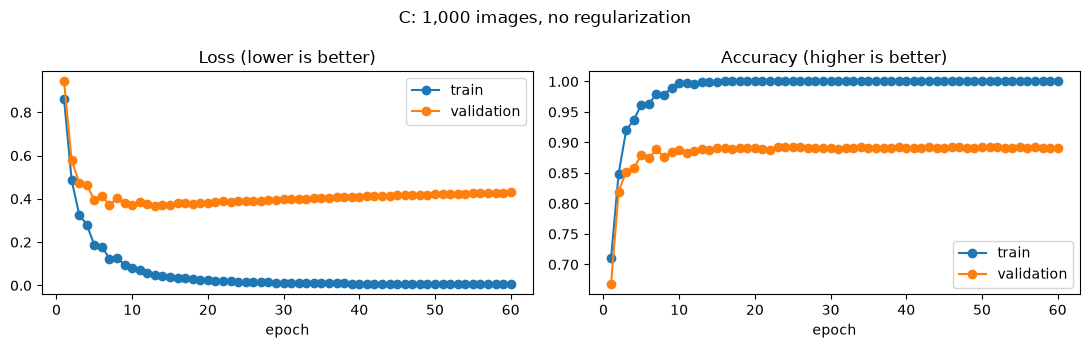

{'experiment': 'C: 1,000 images, no regularization', 'params': 407050, 'train acc': 1.0, 'val acc': 0.8913, 'val loss': 0.43}


In [25]:
small = Subset(train_set, range(1000))
small_loader = DataLoader(small, batch_size=64, shuffle=True)
small_eval = DataLoader(small, batch_size=1000)

torch.manual_seed(42)
_, h_over = run("C: 1,000 images, no regularization", MLP(512), epochs=60,
                loader=small_loader, train_eval=small_eval, plot=True)

Training accuracy reaches 100% while validation loss bottoms out and then slowly **rises**: the model is memorizing.
Validation *accuracy* stays flat. The model isn't getting more answers wrong; it's becoming over-confident
on the ones it gets wrong, which loss detects and accuracy doesn't.
The epoch with the lowest validation loss is where we should have stopped (**early stopping**).

Now add two common fixes: **dropout** (randomly switch off half the hidden neurons during training)
and **weight decay** (penalize large weights).

Without regularization, validation loss was lowest at epoch 13


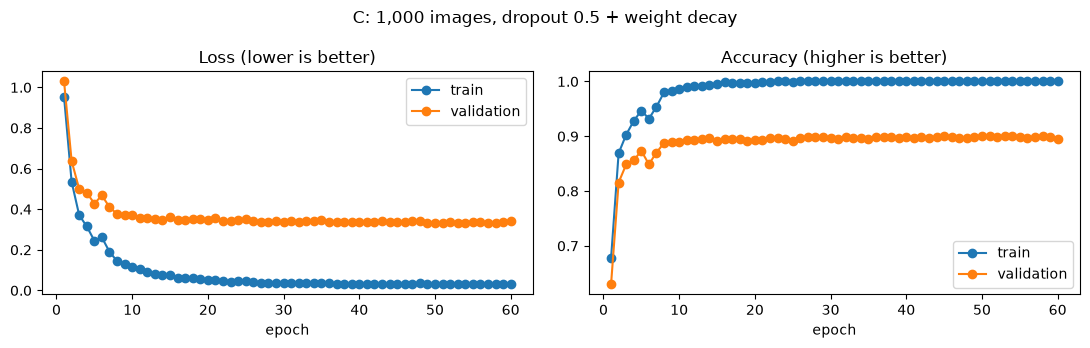

{'experiment': 'C: 1,000 images, dropout 0.5 + weight decay', 'params': 407050, 'train acc': 1.0, 'val acc': 0.8957, 'val loss': 0.34}


In [26]:
best_epoch = int(np.argmin(h_over["val_loss"])) + 1
print(f"Without regularization, validation loss was lowest at epoch {best_epoch}")

torch.manual_seed(42)
_, h_reg = run("C: 1,000 images, dropout 0.5 + weight decay", MLP(512, dropout=0.5), epochs=60,
               weight_decay=1e-2, loader=small_loader, train_eval=small_eval, plot=True)

**Questions:**
- Compare the two validation-loss curves. What did regularization change?
- How much did validation accuracy improve? Compare that with Section 5, which used 50× more training images.
  Which helped more: regularization or more data?

### Experiment D: a convolutional network (CNN)
A CNN slides small 3 × 3 filters across the image, so it looks for local patterns (edges, curves)
wherever they appear, instead of learning a separate weight for every pixel position.

**Predict first:** this CNN has about **one-fifth** the parameters of our MLP. Better or worse?

In [27]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # → 16 × 14 × 14
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # → 32 × 7 × 7
            nn.Flatten(), nn.Linear(32 * 7 * 7, 10))

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
cnn, _ = run("D: CNN", CNN(), epochs=3, lr=0.1)

{'experiment': 'D: CNN', 'params': 20490, 'train acc': 0.9897, 'val acc': 0.9818, 'val loss': 0.057}


In [28]:
torch.manual_seed(42)
mlp, _ = run("D: MLP (same 3 epochs, for comparison)", MLP(), epochs=3, lr=0.1)

{'experiment': 'D: MLP (same 3 epochs, for comparison)', 'params': 101770, 'train acc': 0.9706, 'val acc': 0.9575, 'val loss': 0.139}


### Experiment E: when the world changes (distribution shift)
Models are trained on one kind of data. What if real-world data looks a little different?

**Shift test:** move every validation image right by a few pixels.
**Predict first:** which model handles this better, MLP or CNN?

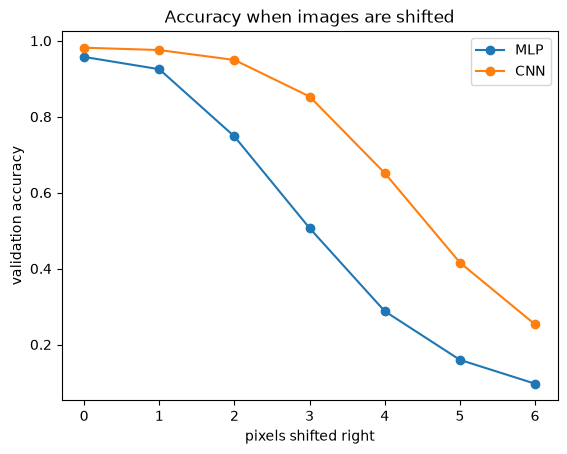

,shift,MLP,CNN
0,0,0.958,0.982
1,1,0.925,0.976
2,2,0.748,0.950
3,3,0.506,0.853
4,4,0.288,0.652
5,5,0.160,0.416
6,6,0.097,0.253


In [29]:
def shifted_accuracy(model, pixels):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in val_loader:
            x = torch.roll(x, shifts=pixels, dims=3)   # shift right (background wraps around)
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item(); total += len(y)
    return correct / total

shifts = [0, 1, 2, 3, 4, 5, 6]
mlp_acc = [shifted_accuracy(mlp, s) for s in shifts]
cnn_acc = [shifted_accuracy(cnn, s) for s in shifts]
plt.plot(shifts, mlp_acc, "o-", label="MLP"); plt.plot(shifts, cnn_acc, "o-", label="CNN")
plt.xlabel("pixels shifted right"); plt.ylabel("validation accuracy"); plt.legend()
plt.title("Accuracy when images are shifted"); plt.show()
pd.DataFrame({"shift": shifts, "MLP": mlp_acc, "CNN": cnn_acc}).round(3)

**Inversion test:** black digits on a white background, something the model never saw in training.

In [30]:
inv_transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda t: 1 - t),
                                    transforms.Normalize((MEAN,), (STD,))])
inv_loader = DataLoader(Subset(datasets.MNIST("data", train=True, transform=inv_transform), val_set.indices),
                        batch_size=1000)
print(f"MLP on inverted images: {evaluate(mlp, inv_loader)[1]:.1%}")
print(f"CNN on inverted images: {evaluate(cnn, inv_loader)[1]:.1%}")

MLP on inverted images: 4.1%
CNN on inverted images: 30.5%


A human reads inverted digits effortlessly. The models collapse, because they learned patterns in *this*
data, not the concept of a digit. In business terms: a model trained on last year's transactions can fail quietly
when vendors, systems, or fraud schemes change. Models need ongoing **monitoring**.

### Summary of experiments

In [31]:
pd.DataFrame(results)

,experiment,params,train acc,val acc,val loss
0,A: lr=0.001,101770,0.8617,0.8636,0.574
1,A: lr=0.01,101770,0.9283,0.9202,0.271
2,A: lr=0.1,101770,0.9706,0.9575,0.139
3,A: lr=1.0,101770,0.4958,0.4920,1.413
4,B: no hidden layer (logistic regression),7850,0.9023,0.8891,0.377
5,"B: hidden=128, no ReLU",101770,0.8948,0.8828,0.390
6,B: hidden=16,12730,0.9343,0.9239,0.252
7,B: hidden=128,101770,0.9706,0.9575,0.139
8,B: hidden=512,407050,0.9771,0.9620,0.124
9,"C: 1,000 images, no regularization",407050,1.0000,0.8913,0.430


## 8. Wrap-up questions

1. Why did we compute the normalization mean/std from the training data only?
2. Why did experiments use the validation set instead of the test set? What goes wrong if you tune on the test set?
3. In your own words, what does `loss.backward()` compute, and what does `optimizer.step()` do with it?
4. Your model has 98% accuracy. Give two reasons that number might still be misleading.
5. A bank wants to flag fraudulent transactions (0.2% of all transactions). Which metrics would you report, and why?
6. Pick one result from Section 7 that surprised you. Explain why it happened.